# 02 — Phân tích Random Forest (mô hình chính)

Notebook này **hiển thị** kết quả của `python -m src.rf_analysis` (không tính lại), để mọi số liệu
khớp với `reports/results_snapshot.md` §9. Nếu chưa có kết quả, chạy `python -m src.rf_analysis`
(hoặc `python -m src.reproduce`) ở thư mục gốc repo rồi chạy lại notebook.

Nội dung:
1. Validation curve theo `n_estimators` và `max_depth` — tham số đã tune nằm ở đâu trên đường bias–variance.
2. OOB vs cross-validation vs test.
3. Độ quan trọng đặc trưng theo 3 cách: MDI, permutation, SHAP — và mức đồng thuận giữa chúng.
4. Giải thích cục bộ (SHAP) cho 3 khách hàng: TP, FN, FP.

**Đổi `DATASET`** sang dataset chính sau khi chốt D1 (`'ibm'` hoặc `'iranian'`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

DATASET = 'ibm'   # 'ibm' | 'iranian' | 'orange'
RESULTS = ROOT / 'results' / 'rf_analysis'
FIGURES = ROOT / 'figures' / 'rf'

local_csv = RESULTS / f'{DATASET}_local_shap.csv'
if not (RESULTS / f'{DATASET}_importance.csv').exists() or not local_csv.exists() \
        or 'rf_score' not in pd.read_csv(local_csv, nrows=0).columns:
    raise FileNotFoundError(
        f'Chưa có kết quả (hoặc kết quả cũ) cho {DATASET!r}. Ở thư mục gốc repo, chạy: '
        f'python -m src.rf_analysis --dataset {DATASET}'
    )

pd.set_option('display.max_colwidth', 80)

## 1. Validation curve

Trục tung là average precision (AP) trên cross-validation của **tập train**. Khoảng cách giữa đường
Train và đường CV thể hiện mức overfit; đường CV đi ngang nghĩa là tăng tham số không còn lợi.
Đường nét đứt là giá trị đã chọn khi tune.

,param,value,train_mean,train_std,cv_mean,cv_std
0,n_estimators,50.0,0.7915,0.0047,0.6559,0.0271
1,n_estimators,100.0,0.7932,0.0058,0.6599,0.0273
2,n_estimators,200.0,0.7947,0.0052,0.6617,0.0260
3,n_estimators,300.0,0.7955,0.0055,0.6617,0.0260
4,n_estimators,500.0,0.7961,0.0056,0.6632,0.0243
5,max_depth,3.0,0.6539,0.0064,0.6436,0.0204
6,max_depth,5.0,0.6838,0.0062,0.6566,0.0231
7,max_depth,8.0,0.7515,0.0061,0.6636,0.0239
8,max_depth,10.0,0.7961,0.0056,0.6632,0.0243
9,max_depth,12.0,0.8221,0.0043,0.6609,0.0264


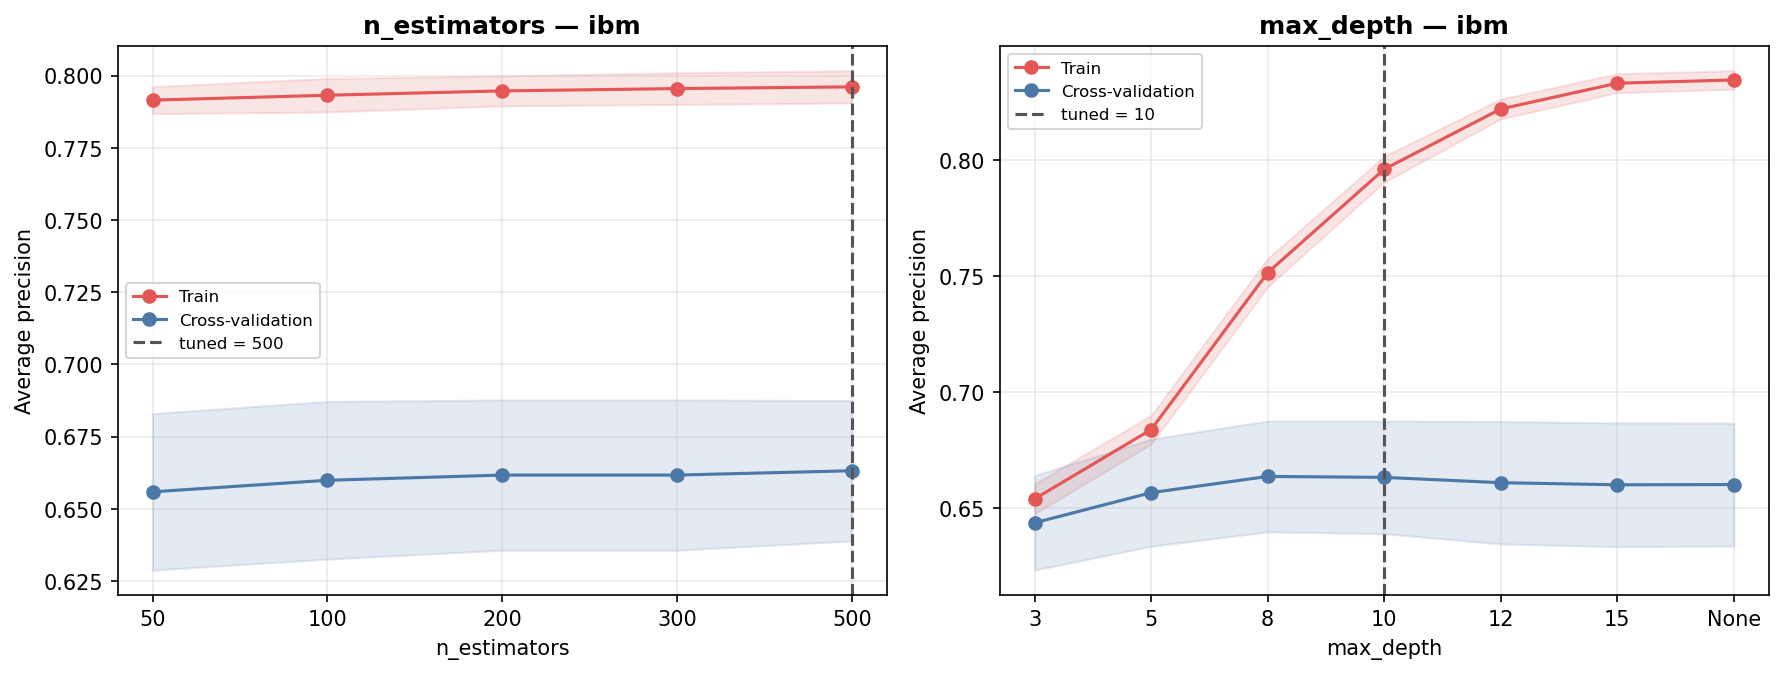

In [2]:
display(pd.read_csv(RESULTS / f'{DATASET}_validation_curve.csv'))
display(Image(filename=str(FIGURES / f'validation_curve_{DATASET}.png')))

## 2. OOB vs CV vs test

OOB (out-of-bag) là ước lượng "miễn phí" của RF: mỗi cây được đánh giá trên các dòng không nằm
trong mẫu bootstrap của nó. Nếu OOB ≈ CV ≈ test thì đánh giá đáng tin. Với Iranian, OOB có thể
lạc quan vì một bản trùng có thể nằm trong mẫu bootstrap trong khi bản kia là OOB.

In [3]:
summary = pd.read_csv(RESULTS / 'rf_summary.csv')
display(summary[summary['dataset'] == DATASET].T)

,0
dataset,ibm
n_estimators,500
max_depth,10.0
oob_ap,0.6623
oob_roc_auc,0.8461
cv_ap_mean,0.6632
cv_ap_std,0.0243
test_ap,0.665
test_roc_auc,0.8514
spearman_mdi_permutation,0.843


## 3. Độ quan trọng đặc trưng — 3 cách

- **MDI**: tổng mức giảm impurity; nhanh nhưng thiên vị biến có nhiều giá trị và tính trên tập train.
- **Permutation**: AP trên test giảm bao nhiêu khi xáo trộn một cột gốc; phản ánh đúng hiệu năng,
  nhưng chia điểm giữa các biến tương quan (có thể âm).
- **SHAP**: đóng góp trung bình |SHAP| của từng biến vào xác suất dự đoán.

Hệ số Spearman (ρ) trong bảng ở mục 2 cho biết các cách xếp hạng có đồng thuận không.

,feature,mdi,permutation,shap,mdi_rank,permutation_rank,shap_rank
0,charges_per_tenure,0.20309,NaN,0.07394,1.0,NaN,1.0
1,Contract,0.11422,0.04883,0.06997,3.0,2.0,2.0
2,InternetService,0.07037,0.03082,0.05514,5.0,3.0,3.0
3,tenure,0.13652,0.16655,0.05512,2.0,1.0,4.0
4,is_high_risk_contract,0.06261,NaN,0.03586,6.0,NaN,5.0
5,PaymentMethod,0.05122,0.01027,0.02569,7.0,8.0,6.0
6,security_support_services,0.03332,NaN,0.02427,8.0,NaN,7.0
7,TechSupport,0.03228,0.01899,0.02189,9.0,5.0,8.0
8,MonthlyCharges,0.07430,0.02757,0.02068,4.0,4.0,9.0
9,OnlineSecurity,0.03037,0.01432,0.02025,10.0,6.0,10.0


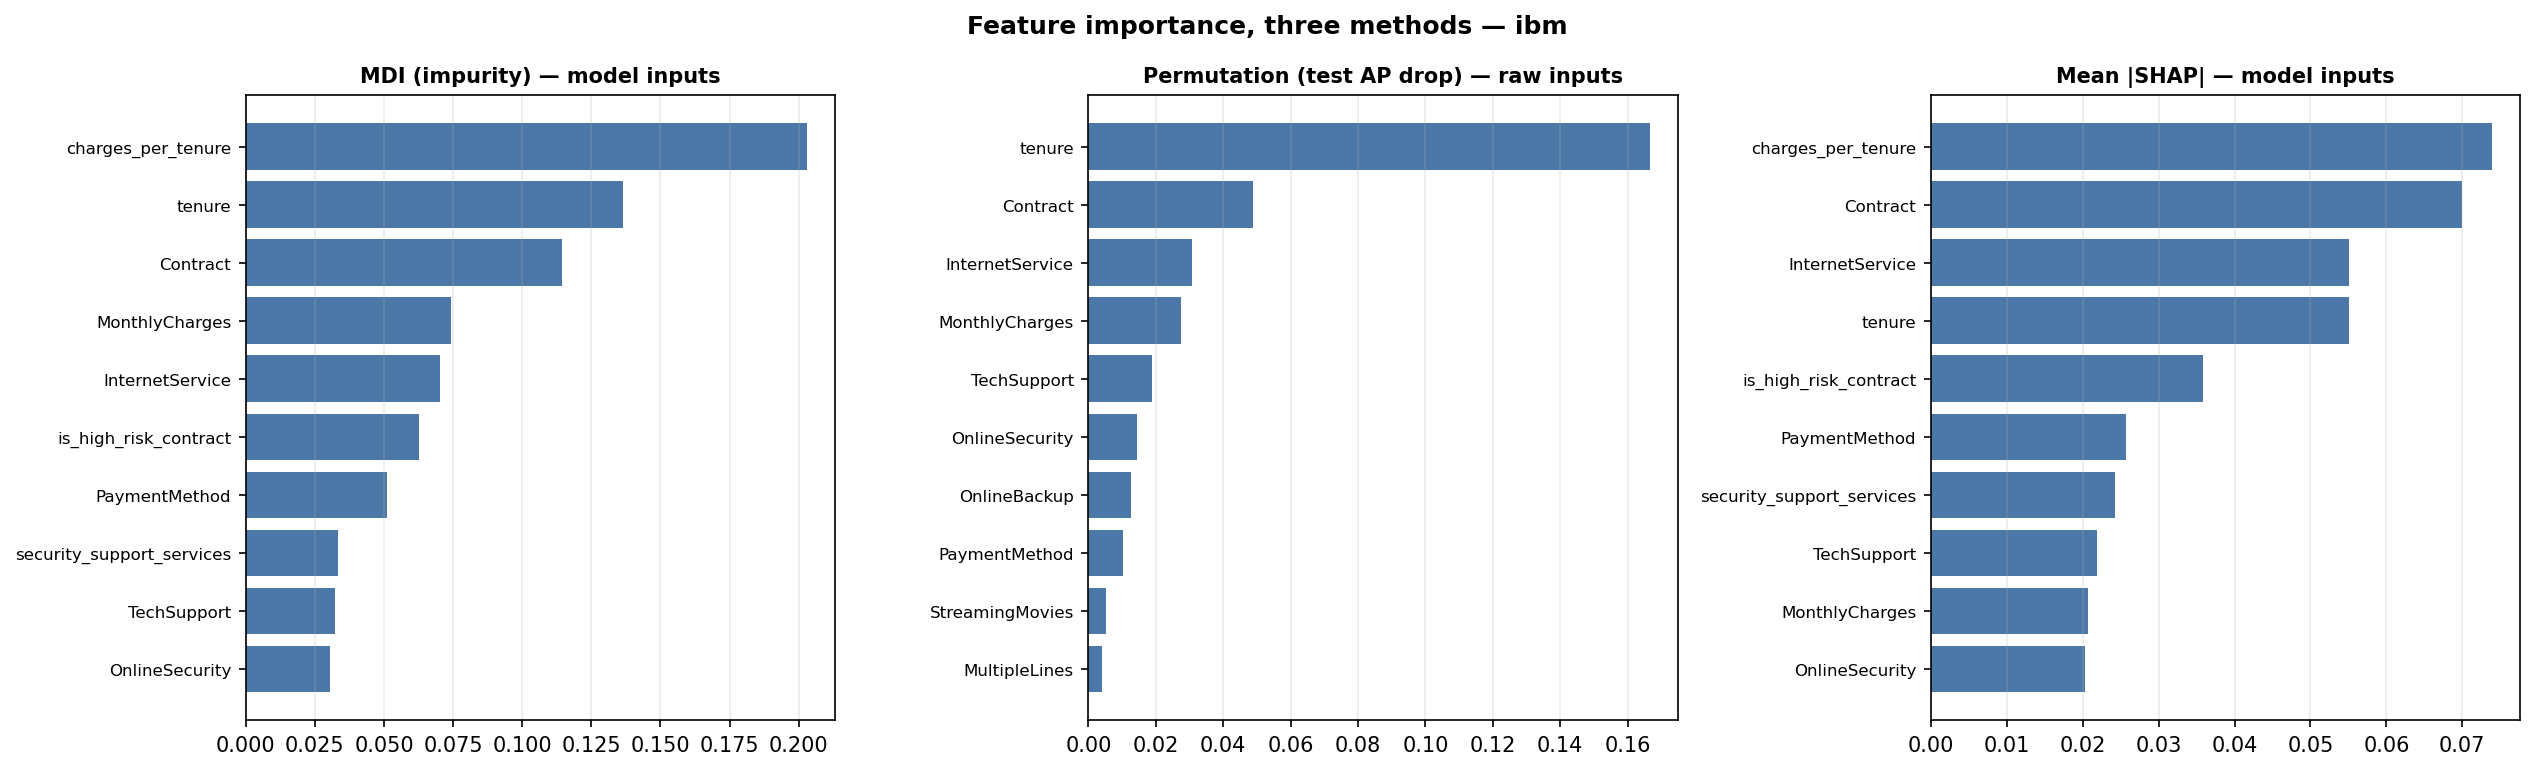

In [4]:
importance = pd.read_csv(RESULTS / f'{DATASET}_importance.csv')
display(importance.head(12))
display(Image(filename=str(FIGURES / f'importance_methods_{DATASET}.png')))

## 4. Giải thích cục bộ — vì sao mô hình đúng/sai với từng khách

Thanh đỏ đẩy điểm churn của rừng **lên**, thanh xanh kéo **xuống**. `rf_score` là điểm của rừng
chưa calibrate (đại lượng mà SHAP phân rã). Model deploy áp thêm một hàm sigmoid đơn điệu lên điểm này:
thứ hạng rủi ro giữa các khách giữ nguyên, nhưng giá trị SHAP không chuyển nguyên vẹn qua một hàm phi
tuyến, nên trên thang xác suất đã calibrate độ lớn và thứ tự các yếu tố có thể khác đôi chút. FN (bỏ sót) và FP (báo nhầm) là
chất liệu tốt cho phần thảo luận hạn chế của mô hình. Đây là tương quan mà mô hình học được,
**không phải quan hệ nhân quả**.

,case,rf_score,actual_churn,rank,feature,value,contribution
0,TP (most confident churner caught),0.9422,1,1,charges_per_tenure,47.725,0.0995
1,TP (most confident churner caught),0.9422,1,2,tenure,1,0.0634
2,TP (most confident churner caught),0.9422,1,3,InternetService,Fiber optic,0.0529
3,TP (most confident churner caught),0.9422,1,4,is_high_risk_contract,1,0.0401
4,TP (most confident churner caught),0.9422,1,5,Contract,Month-to-month,0.0383
5,TP (most confident churner caught),0.9422,1,6,PaymentMethod,Electronic check,0.0243
6,FN (churner most clearly missed),0.0916,1,1,charges_per_tenure,1.2316326530612245,-0.1085
7,FN (churner most clearly missed),0.0916,1,2,tenure,48,-0.0644
8,FN (churner most clearly missed),0.0916,1,3,InternetService,DSL,-0.0383
9,FN (churner most clearly missed),0.0916,1,4,Contract,One year,-0.0335


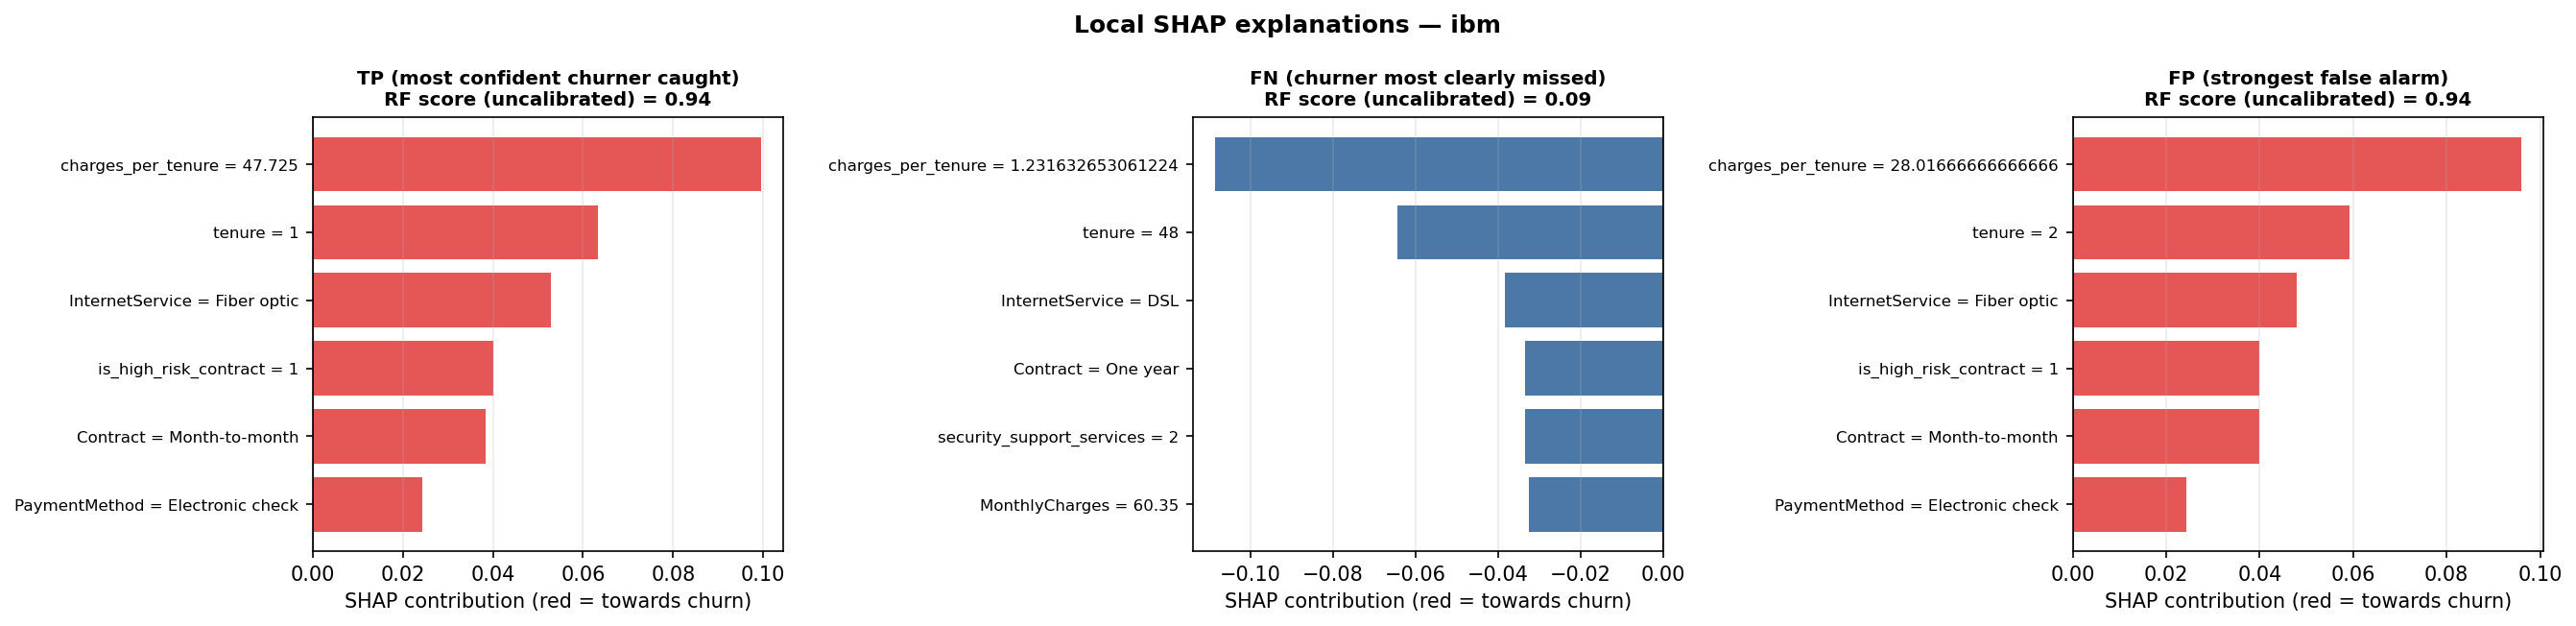

In [5]:
local = pd.read_csv(RESULTS / f'{DATASET}_local_shap.csv')
display(local[['case', 'rf_score', 'actual_churn', 'rank', 'feature', 'value', 'contribution']])
display(Image(filename=str(FIGURES / f'local_shap_{DATASET}.png')))

## 5. Calibration (bổ sung)

Reliability diagram của các cách calibrate (từ `python -m src.calibration_analysis`), dùng cho
mục 5.2 và cho Nhật Linh ở mục 5.3. Bảng số cần chạy `python -m src.calibration_analysis` trước.

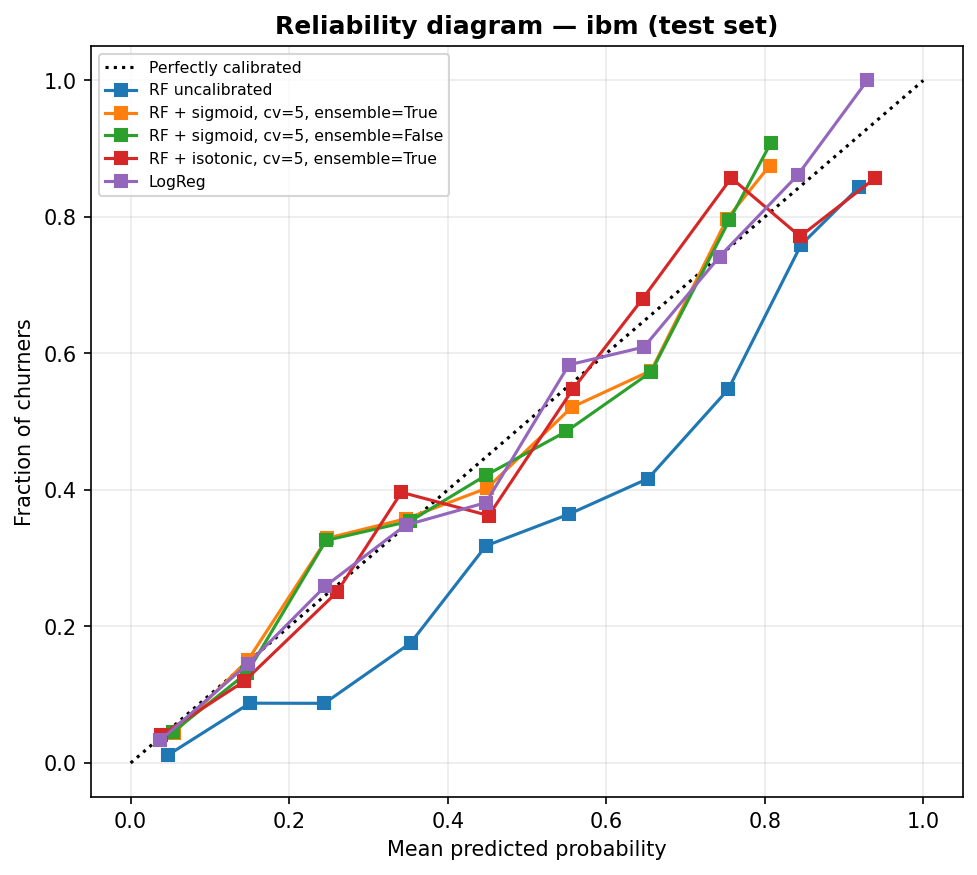

,dataset,model,deployed,roc_auc,average_precision,brier_score,log_loss,ece,mean_proba,test_churn_rate,val_average_precision,val_brier_score,val_ece,fit_seconds,size_mb,size_mb_compressed
0,ibm,RF uncalibrated,False,0.8514,0.6650,0.1521,0.4575,0.1214,0.3863,0.2649,0.6275,0.1549,0.1107,1.54,16.97,6.67
1,ibm,"RF + sigmoid, cv=5, ensemble=True",False,0.8518,0.6627,0.1345,0.4135,0.0277,0.2694,0.2649,0.6281,0.1381,0.0147,7.99,73.93,28.64
2,ibm,"RF + sigmoid, cv=5, ensemble=False",True,0.8514,0.6650,0.1345,0.4136,0.0292,0.2720,0.2649,0.6275,0.1383,0.0243,6.20,16.95,6.64
3,ibm,"RF + isotonic, cv=5, ensemble=True",False,0.8512,0.6606,0.1336,0.4093,0.0260,0.2684,0.2649,0.6279,0.1390,0.0309,4.43,73.93,28.64
4,ibm,LogReg,False,0.8527,0.6723,0.1330,0.4050,0.0155,0.2703,0.2649,0.6389,0.1386,0.0266,0.22,0.01,0.00


In [6]:
path = FIGURES / f'reliability_{DATASET}.png'
table = ROOT / 'results' / 'calibration' / 'calibration_comparison.csv'
if path.exists() and table.exists():
    display(Image(filename=str(path)))
    display(pd.read_csv(table))
else:
    print('Chưa có: chạy python -m src.calibration_analysis --dataset', DATASET)